# **Applied AI in Biomedicine**
## Practical Lesson 3
### CV techniques

**Professor:** Valentina Corino

**Teaching assistant:** Meri Ferretti &lt;meri.ferretti@polimi.it&gt;

---


In [3]:
# support functions
from scipy.io import loadmat
import numpy as np, os, sys, joblib
from tqdm import tqdm
import pandas as pd
from collections import Counter
import matplotlib.pyplot as plt
from scipy.signal import butter, lfilter
from scipy import stats
from sklearn.model_selection import train_test_split
import random
import seaborn as sns
from sklearn import svm
from sklearn.metrics import accuracy_score, f1_score, recall_score, confusion_matrix, roc_auc_score, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler, NearMiss, TomekLinks
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from sklearn.feature_selection import VarianceThreshold
from itertools import compress
from sklearn.linear_model import Lasso
from sklearn.feature_selection import SelectFromModel
from sklearn.feature_selection import RFE
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier, RandomForestClassifier, StackingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
import shap


# reproducibility
SEED = 0
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)


# 2. Hold-out Validation

In [4]:
features = pd.read_csv(r"features_full.csv")
features = features.set_index('ID') # use ID as index not as feature

features

,age,sex,label,mean_RR,mean_Peaks,median_RR,median_Peaks,std_RR,std_Peaks,var_RR,...,EL_SVG,EL_SVG_M,QRS_Mag,QRS_Mag_M,T_Mag,T_Mag_M,SVG_Mag,QT_interval,AUC_VM_QT,WVG
ID,,,,,,,,,,,,,,,,,,,,,
A0823,29.0,0,0,626.500000,5.403650e+05,725.0,6.168093e+05,173.470314,2.232200e+05,31675.736842,...,56.014235,57.389989,5.757267e+05,1.565570e+07,164200.172718,1.446059e+07,6.389319e+05,358.0,5.278774e+07,2.004804e+07
A0805,60.0,1,0,594.125000,6.038188e+06,604.0,6.374080e+06,41.397275,1.540985e+06,1827.983333,...,40.684923,45.177466,7.333811e+05,2.751523e+07,58626.498164,1.339862e+07,6.791215e+05,258.0,5.956400e+07,1.446827e+07
A0841,30.0,1,0,634.774194,3.408983e+06,644.0,3.476986e+06,44.494806,8.214676e+05,2045.780645,...,59.241021,76.261626,7.429733e+05,3.727852e+07,285525.338022,2.497948e+07,7.565434e+05,302.0,1.075152e+08,4.739547e+07
A0836,37.0,1,1,399.376344,2.527253e+05,360.0,3.478365e+05,149.820245,2.131484e+05,22690.085086,...,46.148965,49.675890,5.870813e+05,2.151710e+07,111738.676057,1.116458e+07,5.111130e+05,308.0,4.339884e+07,1.359066e+07
A0848,90.0,1,1,480.894118,1.977902e+05,482.0,2.525434e+05,156.905518,1.099769e+05,24912.429132,...,80.860389,73.083694,4.715546e+05,2.329259e+07,357247.744320,3.772234e+07,5.760547e+05,404.0,7.028715e+07,4.185395e+07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
A0803,51.0,1,0,398.166667,2.277756e+05,350.0,2.409826e+04,85.095861,2.185332e+05,7556.144928,...,74.443093,79.760609,8.663423e+05,5.571063e+07,321738.042216,4.474773e+07,5.684053e+05,294.0,1.176203e+08,1.540408e+07
A0824,22.0,1,0,426.818182,1.742223e+05,400.0,2.210908e+04,121.299268,1.638761e+05,15055.687104,...,58.827567,61.925544,7.370448e+05,3.584437e+07,246880.813594,2.252404e+07,9.724770e+05,320.0,6.893324e+07,5.748949e+07
A0827,28.0,0,0,472.514286,5.660042e+04,426.0,5.414103e+04,191.424341,3.163925e+04,37721.021849,...,76.380576,102.067885,1.151615e+06,3.595969e+07,359958.785498,4.385930e+07,1.154136e+06,360.0,1.345750e+08,5.476754e+07


Total training patients: 486
Total validation patients: 122
Total test patients: 152


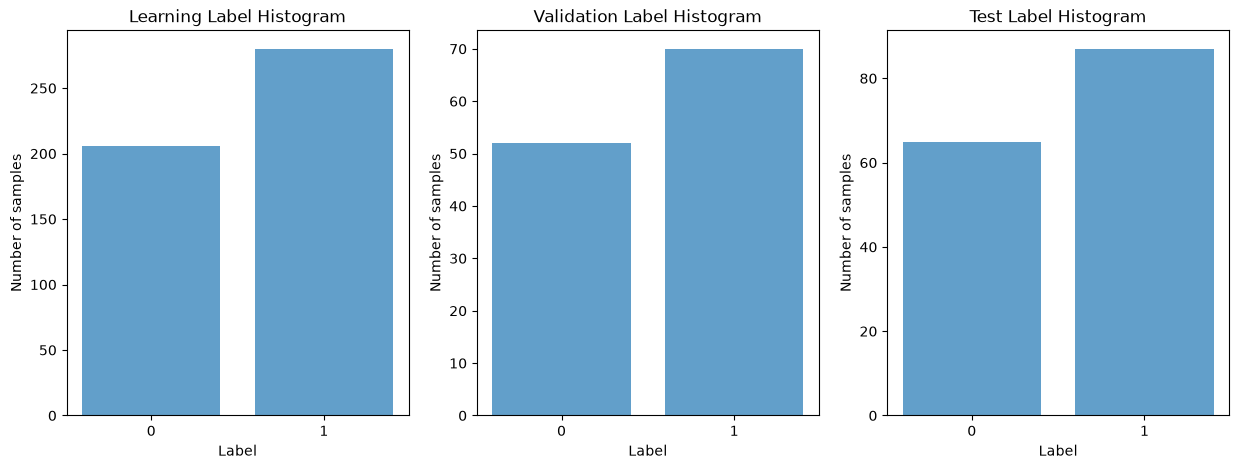

In [5]:
# split the entire dataset into training and test
labels = features.label
training, test = train_test_split(features, test_size=0.2, shuffle=True,
                                  random_state=SEED, stratify=labels)
training_labels = training.label

# further split training set into learning and validation
learning, validation = train_test_split(training, test_size=0.2, shuffle=True,
                                        random_state=SEED, stratify=training_labels)

learning_labels = learning.label
learning_features = learning.drop(columns='label')

validation_labels = validation.label
validation_features = validation.drop(columns='label')

test_labels = test.label
test_features = test.drop(columns='label')

# plot label histograms

# calculate the label counts for train, validation, and test sets
learning_label_counts = learning_labels.value_counts().sort_index()
validation_label_counts = validation_labels.value_counts().sort_index()
test_label_counts = test_labels.value_counts().sort_index()

# create subplots for the histograms
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 5))

# plot histograms for each dataset
ax1.bar(learning_label_counts.index, learning_label_counts.values, align='center', alpha=0.7)
ax1.set_xticks(learning_label_counts.index)
ax1.set_xlabel("Label")
ax1.set_ylabel("Number of samples")
ax1.set_title("Learning Label Histogram")
print('Total training patients: ' + str(np.shape(learning)[0]))


ax2.bar(validation_label_counts.index, validation_label_counts.values, align='center', alpha=0.7)
ax2.set_xticks(validation_label_counts.index)
ax2.set_xlabel("Label")
ax2.set_ylabel("Number of samples")
ax2.set_title("Validation Label Histogram")
print('Total validation patients: ' + str(np.shape(validation)[0]))


ax3.bar(test_label_counts.index, test_label_counts.values, align='center', alpha=0.7)
ax3.set_xticks(test_label_counts.index)
ax3.set_xlabel("Label")
ax3.set_ylabel("Number of samples")
ax3.set_title("Test Label Histogram")
print('Total test patients: ' + str(np.shape(test)[0]))


# K-Fold CV for model evaluation

In [6]:
features = pd.read_csv(r"features_full.csv")
features = features.set_index('ID') # use ID as index not as feature

features

,age,sex,label,mean_RR,mean_Peaks,median_RR,median_Peaks,std_RR,std_Peaks,var_RR,...,EL_SVG,EL_SVG_M,QRS_Mag,QRS_Mag_M,T_Mag,T_Mag_M,SVG_Mag,QT_interval,AUC_VM_QT,WVG
ID,,,,,,,,,,,,,,,,,,,,,
A0823,29.0,0,0,626.500000,5.403650e+05,725.0,6.168093e+05,173.470314,2.232200e+05,31675.736842,...,56.014235,57.389989,5.757267e+05,1.565570e+07,164200.172718,1.446059e+07,6.389319e+05,358.0,5.278774e+07,2.004804e+07
A0805,60.0,1,0,594.125000,6.038188e+06,604.0,6.374080e+06,41.397275,1.540985e+06,1827.983333,...,40.684923,45.177466,7.333811e+05,2.751523e+07,58626.498164,1.339862e+07,6.791215e+05,258.0,5.956400e+07,1.446827e+07
A0841,30.0,1,0,634.774194,3.408983e+06,644.0,3.476986e+06,44.494806,8.214676e+05,2045.780645,...,59.241021,76.261626,7.429733e+05,3.727852e+07,285525.338022,2.497948e+07,7.565434e+05,302.0,1.075152e+08,4.739547e+07
A0836,37.0,1,1,399.376344,2.527253e+05,360.0,3.478365e+05,149.820245,2.131484e+05,22690.085086,...,46.148965,49.675890,5.870813e+05,2.151710e+07,111738.676057,1.116458e+07,5.111130e+05,308.0,4.339884e+07,1.359066e+07
A0848,90.0,1,1,480.894118,1.977902e+05,482.0,2.525434e+05,156.905518,1.099769e+05,24912.429132,...,80.860389,73.083694,4.715546e+05,2.329259e+07,357247.744320,3.772234e+07,5.760547e+05,404.0,7.028715e+07,4.185395e+07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
A0803,51.0,1,0,398.166667,2.277756e+05,350.0,2.409826e+04,85.095861,2.185332e+05,7556.144928,...,74.443093,79.760609,8.663423e+05,5.571063e+07,321738.042216,4.474773e+07,5.684053e+05,294.0,1.176203e+08,1.540408e+07
A0824,22.0,1,0,426.818182,1.742223e+05,400.0,2.210908e+04,121.299268,1.638761e+05,15055.687104,...,58.827567,61.925544,7.370448e+05,3.584437e+07,246880.813594,2.252404e+07,9.724770e+05,320.0,6.893324e+07,5.748949e+07
A0827,28.0,0,0,472.514286,5.660042e+04,426.0,5.414103e+04,191.424341,3.163925e+04,37721.021849,...,76.380576,102.067885,1.151615e+06,3.595969e+07,359958.785498,4.385930e+07,1.154136e+06,360.0,1.345750e+08,5.476754e+07


In [7]:
def get_metrics(labels, labels_pred, probs):
        cm = confusion_matrix(labels, labels_pred)
        tn, fp, fn, tp = cm.ravel()
        accuracy = accuracy_score(labels, labels_pred)
        f1 = f1_score(labels, labels_pred)
        sensitivity = recall_score(labels, labels_pred)  # Same as
        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
        auc = roc_auc_score(labels, probs)
        return accuracy, f1, sensitivity, specificity, auc

In [8]:
# Import CV function from scikit-learn library
from sklearn.model_selection import StratifiedKFold

# Split the entire dataset into training and test
labels = features.label
training, test = train_test_split(features, test_size=0.2, shuffle=True,
                                  random_state=SEED, stratify=labels)

training_features = training.drop(columns='label')
training_labels = training.label

test_labels = test.label
test_features = test.drop(columns='label')

# Define 5-Fold CV
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Containers to store results during iterations
results = {
    "learning_accuracy": [],
    "validation_accuracy": [],
    "learning_f1": [],
    "validation_f1": [],
    "learning_sensitivity": [],
    "validation_sensitivity": [],
    "learning_specificity": [],
    "validation_specificity": [],
    "learning_auc": [],
    "validation_auc": []
}

# Iteratively split training set into learning and validation
for learning_index, validation_index in kf.split(training_features, training_labels):

    learning_features, validation_features = (training_features.iloc[learning_index],
                                              training_features.iloc[validation_index])

    learning_labels, validation_labels = (training_labels.iloc[learning_index],
                                          training_labels.iloc[validation_index])

    # -----------------------------------
    # 1. Outliers' removal (IQR method)
    # -----------------------------------

    # Learn bounds from learning set
    feature_list = learning_features.columns
    outlier_flags = pd.DataFrame(False, index=learning_features.index, columns=feature_list)
    iqr_bounds = {}

    for col in feature_list:
        Q1 = learning_features[col].quantile(0.25)
        Q3 = learning_features[col].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        iqr_bounds[col] = (lower_bound, upper_bound)
        outliers = (learning_features[col] < lower_bound) | (learning_features[col] > upper_bound)
        outlier_flags[col] = outliers
        learning_features.loc[outliers, col] = np.nan

    learning_features = pd.DataFrame(data=learning_features, columns=feature_list)

    # Apply to validation set
    outlier_flags = pd.DataFrame(False, index=validation_features.index, columns=validation_features.columns)

    for col in validation_features.columns:
        lower_bound, upper_bound = iqr_bounds[col]
        outliers = (validation_features[col] < lower_bound) | (validation_features[col] > upper_bound)
        outlier_flags[col] = outliers
        validation_features.loc[outliers, col] = np.nan

    validation_features =  pd.DataFrame(data=validation_features, columns=feature_list)

    # ----------------------------------------------
    # 2. Missing data handling (kNN imputation)
    # ----------------------------------------------

    # Fit the Imputer on learning set
    imputer = KNNImputer(n_neighbors=10, weights='uniform', metric='nan_euclidean')
    imputer.fit(learning_features)
    feature_list = learning_features.columns
    learning_features = imputer.transform(learning_features)
    learning_features =  pd.DataFrame(data=learning_features, columns=feature_list)

    # Apply to validation set
    validation_features = imputer.transform(validation_features)
    validation_features =  pd.DataFrame(data=validation_features, columns=feature_list)

    # -----------------------------------
    # 3. Class balancing (NearMiss-1)
    # -----------------------------------

    # Balancing only learning set
    nearmiss = NearMiss(version=1) # using NearMiss-1
    learning_features, learning_labels = nearmiss.fit_resample(learning_features, learning_labels)


    # -----------------------------------
    # 4. Feature scaling (Min-max)
    # -----------------------------------

    # Fit the scaler on the learning set
    scaler = MinMaxScaler(feature_range=(0, 1)) # for standard scaling use StandardScaler(), for RobustScaling use RobustScaler()
    scaler.fit(learning_features)
    feature_list = learning_features.columns
    learning_features = scaler.transform(learning_features)
    learning_features = pd.DataFrame(data=learning_features, columns=feature_list)

    # Apply to validation set
    validation_features = scaler.transform(validation_features)
    validation_features = pd.DataFrame(data=validation_features, columns=feature_list)


    # -------------------------------------
    # 5. Feature selection (Corr + RFE)
    # -------------------------------------

    # Identify highly correlated features on learning set
    corr_matrix = learning_features.corr().abs()
    correlated_features = set()
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    median_corr = corr_matrix.median(axis=0)  # calculates the median correlation of each feature with all other features
    to_drop = set()
    for column in upper.columns:
        for row in upper.index:
            if pd.notna(upper.loc[row, column]) and upper.loc[row, column] > 0.80:
                if median_corr[row] > median_corr[column]:
                    to_drop.add(row)
                else:
                    to_drop.add(column)
    learning_features.drop(columns=to_drop, inplace=True)

    # Apply to validation set
    validation_features.drop(columns=to_drop, inplace=True)


    # Perform RFE on learning set
    estimator = SVC(kernel="linear")
    selector = RFE(estimator=estimator, n_features_to_select=10, step=1)
    selector.fit(learning_features, learning_labels)
    selected_features = learning_features.columns[selector.support_]
    learning_features = learning_features[selected_features]

    # Apply to validation set
    validation_features = validation_features[selected_features]


    # ---------------------------------------
    # 6. Classifier (Logistic Regression)
    # ---------------------------------------

    model = LogisticRegression(
        penalty='l2',             # L2 regularization
        C=1.0,                    # Regularization strength
        solver='lbfgs',           # Optimization algorithm
        max_iter=1000,            # Maximum iterations
        class_weight='balanced',  # Adjust weights inversely proportional to class frequencies
        random_state=42
    )

    # Train the model on learning set
    model.fit(learning_features, learning_labels)
    learning_labels_pred = model.predict(learning_features)
    learning_probs = model.predict_proba(learning_features)[:, 1]
    learning_accuracy, learning_f1, learning_sensitivity, learning_specificity, learning_auc = get_metrics(learning_labels, learning_labels_pred, learning_probs)

    # Apply to validation set
    validation_labels_pred = model.predict(validation_features)
    validation_probs = model.predict_proba(validation_features)[:, 1]
    validation_accuracy, validation_f1, validation_sensitivity, validation_specificity, validation_auc = get_metrics(validation_labels, validation_labels_pred, validation_probs)

    # Store fold results
    results["learning_accuracy"].append(learning_accuracy)
    results["validation_accuracy"].append(validation_accuracy)
    results["learning_f1"].append(learning_f1)
    results["validation_f1"].append(validation_f1)
    results["learning_sensitivity"].append(learning_sensitivity)
    results["validation_sensitivity"].append(validation_sensitivity)
    results["learning_specificity"].append(learning_specificity)
    results["validation_specificity"].append(validation_specificity)
    results["learning_auc"].append(learning_auc)
    results["validation_auc"].append(validation_auc)


####  Re-train on entire training set

# -----------------------------------
# 1. Outliers' removal (IQR method)
# -----------------------------------

# Learn bounds from learning set
feature_list = training_features.columns
outlier_flags = pd.DataFrame(False, index=learning_features.index, columns=feature_list)
iqr_bounds = {}

for col in feature_list:
    Q1 = training_features[col].quantile(0.25)
    Q3 = training_features[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    iqr_bounds[col] = (lower_bound, upper_bound)
    outliers = (training_features[col] < lower_bound) | (training_features[col] > upper_bound)
    outlier_flags[col] = outliers
    training_features.loc[outliers, col] = np.nan

training_features = pd.DataFrame(data=training_features, columns=feature_list)

# Apply to test set
outlier_flags = pd.DataFrame(False, index=test_features.index, columns=test_features.columns)

for col in test_features.columns:
    lower_bound, upper_bound = iqr_bounds[col]
    outliers = (test_features[col] < lower_bound) | (test_features[col] > upper_bound)
    outlier_flags[col] = outliers
    test_features.loc[outliers, col] = np.nan

test_features =  pd.DataFrame(data=test_features, columns=feature_list)

# ---------------------------------------------
# 2. Missing data handling (kNN imputation)
# ---------------------------------------------

# Fit the Imputer on learning set
imputer = KNNImputer(n_neighbors=10, weights='uniform', metric='nan_euclidean')
imputer.fit(training_features)
feature_list = training_features.columns
training_features = imputer.transform(training_features)
training_features =  pd.DataFrame(data=training_features, columns=feature_list)

# Apply on test set
test_features = imputer.transform(test_features)
test_features =  pd.DataFrame(data=test_features, columns=feature_list)


# -----------------------------------
# 3. Class balancing (NearMiss-1)
# -----------------------------------

# Balancing only training set
nearmiss = NearMiss(version=1) # using NearMiss-1
training_features, training_labels = nearmiss.fit_resample(training_features, training_labels)


# -----------------------------------
# 4. Feature scaling (Min-max)
# -----------------------------------

# Fit the scaler on the training set
scaler = MinMaxScaler(feature_range=(0, 1)) # for standard scaling use StandardScaler(), for RobustScaling use RobustScaler()
scaler.fit(training_features)
feature_list = training_features.columns
training_features = scaler.transform(training_features)
training_features = pd.DataFrame(data=training_features, columns=feature_list)

# Apply to test set
test_features = scaler.transform(test_features)
test_features = pd.DataFrame(data=test_features, columns=feature_list)



# 5. Feature selection (Corr + RFE)
# -------------------------------------

# Identify highly correlated features on learning set
corr_matrix = training_features.corr().abs()
correlated_features = set()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
median_corr = corr_matrix.median(axis=0)  # calculates the median correlation of each feature with all other features
to_drop = set()
for column in upper.columns:
    for row in upper.index:
        if pd.notna(upper.loc[row, column]) and upper.loc[row, column] > 0.80:
            if median_corr[row] > median_corr[column]:
                to_drop.add(row)
            else:
                to_drop.add(column)
training_features.drop(columns=to_drop, inplace=True)

# Apply to test set
test_features.drop(columns=to_drop, inplace=True)

# Perform RFE on learning set
estimator = SVC(kernel="linear")
selector = RFE(estimator=estimator, n_features_to_select=10, step=1)
selector.fit(training_features, training_labels)
selected_features = training_features.columns[selector.support_]
training_features = training_features[selected_features]

# Apply to test set
test_features = test_features[selected_features]


# 6. Classifier (Logistic Regression)
# ---------------------------------------
model = LogisticRegression(
    penalty='l2',             # L2 regularization
    C=1.0,                    # Regularization strength
    solver='lbfgs',           # Optimization algorithm
    max_iter=1000,            # Maximum iterations
    class_weight='balanced',  # Adjust weights inversely proportional to class frequencies
    random_state=42
)

# Train the model on training set
model.fit(training_features, training_labels)
training_labels_pred = model.predict(training_features)
training_probs = model.predict_proba(training_features)[:, 1]
training_accuracy, training_f1, training_sensitivity, training_specificity, training_auc = get_metrics(training_labels, training_labels_pred, training_probs)

# Apply to test set
test_labels_pred = model.predict(test_features)
test_probs = model.predict_proba(test_features)[:, 1]
test_accuracy, test_f1, test_sensitivity, test_specificity, test_auc = get_metrics(test_labels, test_labels_pred, test_probs)

print("Mean CV results:")
print("Learning Accuracy    :", round(np.mean(results["learning_accuracy"]), 3), "±", round(np.std(results["learning_accuracy"]), 3), "  Validation Accuracy    :", round(np.mean(results["validation_accuracy"]), 3), "±", round(np.std(results["validation_accuracy"]), 3))
print("Learning F1          :", round(np.mean(results["learning_f1"]), 3), "±", round(np.std(results["learning_f1"]), 3), "  Validation F1          :", round(np.mean(results["validation_f1"]), 3), "±", round(np.std(results["validation_f1"]), 3))
print("Learning Sensitivity :", round(np.mean(results["learning_sensitivity"]), 3), "±", round(np.std(results["learning_sensitivity"]), 3), "   Validation Sensitivity :", round(np.mean(results["validation_sensitivity"]), 3), "±", round(np.std(results["validation_sensitivity"]), 3))
print("Learning Specificity :", round(np.mean(results["learning_specificity"]), 3), "±", round(np.std(results["learning_specificity"]), 3), "  Validation Specificity :", round(np.mean(results["validation_specificity"]), 3), "±", round(np.std(results["validation_specificity"]), 3))
print("Learning AUC         :", round(np.mean(results["learning_auc"]), 3), "±", round(np.std(results["learning_auc"]), 3), "  Validation AUC         :", round(np.mean(results["validation_auc"]), 3), "±", round(np.std(results["validation_auc"]), 3))

print("\n\nFinal re-training results:")
print("Training Accuracy    :", round(training_accuracy, 3), "  Test Accuracy    :", round(test_accuracy, 3))
print("Training F1          :", round(training_f1, 3), "  Test F1          :", round(test_f1, 3))
print("Training Sensitivity :", round(training_sensitivity, 3), "   Test Sensitivity :", round(test_sensitivity, 3))
print("Training Specificity :", round(training_specificity, 3), "  Test Specificity :", round(test_specificity, 3))
print("Training AUC         :", round(training_auc, 3), "  Test AUC         :", round(test_auc, 3))


/home/pachy/Desktop/HPCE/hpcengineering/Applied AI in Biomedicine/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/pachy/Desktop/HPCE/hpcengineering/Applied AI in Biomedicine/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet',

Mean CV results:
Learning Accuracy    : 0.908 ± 0.011   Validation Accuracy    : 0.875 ± 0.027
Learning F1          : 0.91 ± 0.011   Validation F1          : 0.89 ± 0.021
Learning Sensitivity : 0.93 ± 0.012    Validation Sensitivity : 0.877 ± 0.029
Learning Specificity : 0.886 ± 0.01   Validation Specificity : 0.872 ± 0.077
Learning AUC         : 0.957 ± 0.006   Validation AUC         : 0.926 ± 0.032


Final re-training results:
Training Accuracy    : 0.907   Test Accuracy    : 0.868
Training F1          : 0.909   Test F1          : 0.881
Training Sensitivity : 0.93    Test Sensitivity : 0.851
Training Specificity : 0.884   Test Specificity : 0.892
Training AUC         : 0.961   Test AUC         : 0.952


/home/pachy/Desktop/HPCE/hpcengineering/Applied AI in Biomedicine/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


# K-fold CV for tuning

The training process has these major steps:

1. Outlier handling (no tuning needed)

2. Missing data imputation → tune n_neighbors, weights, metric of KNN imputer

3. Balancing (no tuning needed)

4. Scaling (no tuning needed)

5. Feature selection → tune correlation threshold + RFE n_features

6. Classifier → tune regularization parameter C of Logistic Regression classifier


We'll use GridSearchCV:

It splits the training data into folds and evaluates all combinations of hyperparameters.

It keeps track of which combination gives the best performance (here, F1 score).

Once the best combination is found, GridSearchCV re-trains the pipeline on the entire training set using those best parameters.

grid.best_estimator_ is this retrained model.

In [9]:
features = pd.read_csv(r"features_full.csv")
features = features.set_index('ID') # use ID as index not as feature

features

,age,sex,label,mean_RR,mean_Peaks,median_RR,median_Peaks,std_RR,std_Peaks,var_RR,...,EL_SVG,EL_SVG_M,QRS_Mag,QRS_Mag_M,T_Mag,T_Mag_M,SVG_Mag,QT_interval,AUC_VM_QT,WVG
ID,,,,,,,,,,,,,,,,,,,,,
A0823,29.0,0,0,626.500000,5.403650e+05,725.0,6.168093e+05,173.470314,2.232200e+05,31675.736842,...,56.014235,57.389989,5.757267e+05,1.565570e+07,164200.172718,1.446059e+07,6.389319e+05,358.0,5.278774e+07,2.004804e+07
A0805,60.0,1,0,594.125000,6.038188e+06,604.0,6.374080e+06,41.397275,1.540985e+06,1827.983333,...,40.684923,45.177466,7.333811e+05,2.751523e+07,58626.498164,1.339862e+07,6.791215e+05,258.0,5.956400e+07,1.446827e+07
A0841,30.0,1,0,634.774194,3.408983e+06,644.0,3.476986e+06,44.494806,8.214676e+05,2045.780645,...,59.241021,76.261626,7.429733e+05,3.727852e+07,285525.338022,2.497948e+07,7.565434e+05,302.0,1.075152e+08,4.739547e+07
A0836,37.0,1,1,399.376344,2.527253e+05,360.0,3.478365e+05,149.820245,2.131484e+05,22690.085086,...,46.148965,49.675890,5.870813e+05,2.151710e+07,111738.676057,1.116458e+07,5.111130e+05,308.0,4.339884e+07,1.359066e+07
A0848,90.0,1,1,480.894118,1.977902e+05,482.0,2.525434e+05,156.905518,1.099769e+05,24912.429132,...,80.860389,73.083694,4.715546e+05,2.329259e+07,357247.744320,3.772234e+07,5.760547e+05,404.0,7.028715e+07,4.185395e+07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
A0803,51.0,1,0,398.166667,2.277756e+05,350.0,2.409826e+04,85.095861,2.185332e+05,7556.144928,...,74.443093,79.760609,8.663423e+05,5.571063e+07,321738.042216,4.474773e+07,5.684053e+05,294.0,1.176203e+08,1.540408e+07
A0824,22.0,1,0,426.818182,1.742223e+05,400.0,2.210908e+04,121.299268,1.638761e+05,15055.687104,...,58.827567,61.925544,7.370448e+05,3.584437e+07,246880.813594,2.252404e+07,9.724770e+05,320.0,6.893324e+07,5.748949e+07
A0827,28.0,0,0,472.514286,5.660042e+04,426.0,5.414103e+04,191.424341,3.163925e+04,37721.021849,...,76.380576,102.067885,1.151615e+06,3.595969e+07,359958.785498,4.385930e+07,1.154136e+06,360.0,1.345750e+08,5.476754e+07


In [10]:
def get_metrics(labels, labels_pred, probs):
        cm = confusion_matrix(labels, labels_pred)
        tn, fp, fn, tp = cm.ravel()
        accuracy = accuracy_score(labels, labels_pred)
        f1 = f1_score(labels, labels_pred)
        sensitivity = recall_score(labels, labels_pred)
        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
        auc = roc_auc_score(labels, probs)
        return accuracy, f1, sensitivity, specificity, auc

In [11]:
from sklearn.base import BaseEstimator, TransformerMixin

class OutlierRemover(BaseEstimator, TransformerMixin):
    def __init__(self, multiplier=1.5):
        self.multiplier = multiplier
        self.bounds_ = {}

    def fit(self, X, y=None):
        X_df = pd.DataFrame(X)
        for col in X_df.columns:
            Q1 = X_df[col].quantile(0.25)
            Q3 = X_df[col].quantile(0.75)
            IQR = Q3 - Q1
            lower = Q1 - self.multiplier * IQR
            upper = Q3 + self.multiplier * IQR
            self.bounds_[col] = (lower, upper)
        return self

    def transform(self, X):
        X_df = pd.DataFrame(X).copy()
        for col, (lower, upper) in self.bounds_.items():
            mask = (X_df[col] < lower) | (X_df[col] > upper)
            X_df.loc[mask, col] = np.nan
        return X_df

In [12]:
class CorrelationFilter(BaseEstimator, TransformerMixin):
    def __init__(self, threshold=0.8):
        self.threshold = threshold
        self.to_drop_ = None

    def fit(self, X, y=None):
        corr_matrix = pd.DataFrame(X).corr().abs()
        upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
        median_corr = corr_matrix.median(axis=0)
        to_drop = set()
        for column in upper.columns:
            for row in upper.index:
                if pd.notna(upper.loc[row, column]) and upper.loc[row, column] > self.threshold:
                    if median_corr[row] > median_corr[column]:
                        to_drop.add(row)
                    else:
                        to_drop.add(column)
        self.to_drop_ = list(to_drop)
        return self

    def transform(self, X):
        X = pd.DataFrame(X)
        if self.to_drop_:
            X = X.drop(columns=self.to_drop_, errors="ignore")
        return X

In [13]:
# Import CV function from scikit-learn library
from sklearn.model_selection import StratifiedKFold, GridSearchCV

# Wrap all the steps to be tuned in a Pipeline object
#from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline

pipeline = Pipeline([
    ('outlier', OutlierRemover()),      # Outlier handling
    ('imputer', KNNImputer()),          # Missing value imputation
    ('nearmiss', NearMiss(version=1)),  # Balancing step
    ('scaler', MinMaxScaler()),         # Feature scaling
    ('corr', CorrelationFilter()),      # Correlation filtering
    ('rfe', RFE(estimator=SVC(kernel="linear"))),  # Feature selection
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))  # Classifier
])

# Define the parameters' grid to test
param_grid = {
    # KNN imputer
    'imputer__n_neighbors': [5, 10],
    'imputer__weights': ['uniform', 'distance'],
    'imputer__metric': ['nan_euclidean'],

    # Correlation filter
    'corr__threshold': [0.75, 0.8],

    # RFE feature selector
    'rfe__n_features_to_select': [5, 10],

    # Logistic Regression
    'clf__C': [0.01, 0.1]
}

# Split the entire dataset into training and test
labels = features.label
training, test = train_test_split(features, test_size=0.2, shuffle=True,
                                  random_state=0, stratify=labels)

training_features = training.drop(columns='label')
training_labels = training.label

test_labels = test.label
test_features = test.drop(columns='label')

# Define the K-Fold CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring='f1',
    n_jobs=-1,
    cv=cv,
    verbose=2,
    return_train_score=True
)

grid.fit(training_features, training_labels)

# Results
best_idx = grid.best_index_ # Index of the best parameters

print("\nBest Parameters:")
for k, v in grid.best_params_.items():
    print(f"   {k}: {v}")

print("\nCV mean results when using best parameters:")
mean_test = grid.cv_results_['mean_test_score'][best_idx]
std_test = grid.cv_results_['std_test_score'][best_idx]
mean_train = grid.cv_results_['mean_train_score'][best_idx]
std_train = grid.cv_results_['std_train_score'][best_idx]

print(f"   Mean Learning F1:      {mean_train:.3f} (+/- {std_train:.3f})")
print(f"   Mean Validation F1:    {mean_test:.3f} (+/- {std_test:.3f})")


# Metrics on training set
best_model = grid.best_estimator_
train_pred = best_model.predict(training_features)
train_prob = best_model.predict_proba(training_features)[:, 1]

train_acc, train_f1, train_sens, train_spec, train_auc = get_metrics(training_labels, train_pred, train_prob)

# Metrics on test set
test_labels_pred = best_model.predict(test_features)
test_labels_prob = best_model.predict_proba(test_features)[:, 1]

test_accuracy, test_f1, test_sens, test_spec, test_auc = get_metrics(test_labels, test_labels_pred, test_labels_prob)

print("\nResults after re-training using best parameters:")
print(f"   Training F1:      {train_f1:.3f}")
print(f"   Test F1:          {test_f1:.3f}")

Fitting 5 folds for each of 32 candidates, totalling 160 fits
[CV] END clf__C=0.01, corr__threshold=0.75, imputer__metric=nan_euclidean, imputer__n_neighbors=5, imputer__weights=uniform, rfe__n_features_to_select=5; total time=   0.6s
[CV] END clf__C=0.01, corr__threshold=0.75, imputer__metric=nan_euclidean, imputer__n_neighbors=5, imputer__weights=uniform, rfe__n_features_to_select=5; total time=   0.6s
[CV] END clf__C=0.01, corr__threshold=0.75, imputer__metric=nan_euclidean, imputer__n_neighbors=5, imputer__weights=uniform, rfe__n_features_to_select=5; total time=   0.6s
[CV] END clf__C=0.01, corr__threshold=0.75, imputer__metric=nan_euclidean, imputer__n_neighbors=5, imputer__weights=uniform, rfe__n_features_to_select=10; total time=   0.6s
[CV] END clf__C=0.01, corr__threshold=0.75, imputer__metric=nan_euclidean, imputer__n_neighbors=5, imputer__weights=uniform, rfe__n_features_to_select=10; total time=   0.6s
[CV] END clf__C=0.01, corr__threshold=0.75, imputer__metric=nan_euclide

# Nested K-fold CV

In [14]:
features = pd.read_csv(r"features_full.csv")
features = features.set_index('ID') # use ID as index not as feature

features

,age,sex,label,mean_RR,mean_Peaks,median_RR,median_Peaks,std_RR,std_Peaks,var_RR,...,EL_SVG,EL_SVG_M,QRS_Mag,QRS_Mag_M,T_Mag,T_Mag_M,SVG_Mag,QT_interval,AUC_VM_QT,WVG
ID,,,,,,,,,,,,,,,,,,,,,
A0823,29.0,0,0,626.500000,5.403650e+05,725.0,6.168093e+05,173.470314,2.232200e+05,31675.736842,...,56.014235,57.389989,5.757267e+05,1.565570e+07,164200.172718,1.446059e+07,6.389319e+05,358.0,5.278774e+07,2.004804e+07
A0805,60.0,1,0,594.125000,6.038188e+06,604.0,6.374080e+06,41.397275,1.540985e+06,1827.983333,...,40.684923,45.177466,7.333811e+05,2.751523e+07,58626.498164,1.339862e+07,6.791215e+05,258.0,5.956400e+07,1.446827e+07
A0841,30.0,1,0,634.774194,3.408983e+06,644.0,3.476986e+06,44.494806,8.214676e+05,2045.780645,...,59.241021,76.261626,7.429733e+05,3.727852e+07,285525.338022,2.497948e+07,7.565434e+05,302.0,1.075152e+08,4.739547e+07
A0836,37.0,1,1,399.376344,2.527253e+05,360.0,3.478365e+05,149.820245,2.131484e+05,22690.085086,...,46.148965,49.675890,5.870813e+05,2.151710e+07,111738.676057,1.116458e+07,5.111130e+05,308.0,4.339884e+07,1.359066e+07
A0848,90.0,1,1,480.894118,1.977902e+05,482.0,2.525434e+05,156.905518,1.099769e+05,24912.429132,...,80.860389,73.083694,4.715546e+05,2.329259e+07,357247.744320,3.772234e+07,5.760547e+05,404.0,7.028715e+07,4.185395e+07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
A0803,51.0,1,0,398.166667,2.277756e+05,350.0,2.409826e+04,85.095861,2.185332e+05,7556.144928,...,74.443093,79.760609,8.663423e+05,5.571063e+07,321738.042216,4.474773e+07,5.684053e+05,294.0,1.176203e+08,1.540408e+07
A0824,22.0,1,0,426.818182,1.742223e+05,400.0,2.210908e+04,121.299268,1.638761e+05,15055.687104,...,58.827567,61.925544,7.370448e+05,3.584437e+07,246880.813594,2.252404e+07,9.724770e+05,320.0,6.893324e+07,5.748949e+07
A0827,28.0,0,0,472.514286,5.660042e+04,426.0,5.414103e+04,191.424341,3.163925e+04,37721.021849,...,76.380576,102.067885,1.151615e+06,3.595969e+07,359958.785498,4.385930e+07,1.154136e+06,360.0,1.345750e+08,5.476754e+07


In [15]:
def get_metrics(labels, labels_pred, probs):
        cm = confusion_matrix(labels, labels_pred)
        tn, fp, fn, tp = cm.ravel()
        accuracy = accuracy_score(labels, labels_pred)
        f1 = f1_score(labels, labels_pred)
        sensitivity = recall_score(labels, labels_pred)  # Same as
        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
        auc = roc_auc_score(labels, probs)
        return accuracy, f1, sensitivity, specificity, auc

In [16]:
from sklearn.base import BaseEstimator, TransformerMixin

class OutlierRemover(BaseEstimator, TransformerMixin):
    def __init__(self, multiplier=1.5):
        self.multiplier = multiplier
        self.bounds_ = {}

    def fit(self, X, y=None):
        X_df = pd.DataFrame(X)
        for col in X_df.columns:
            Q1 = X_df[col].quantile(0.25)
            Q3 = X_df[col].quantile(0.75)
            IQR = Q3 - Q1
            lower = Q1 - self.multiplier * IQR
            upper = Q3 + self.multiplier * IQR
            self.bounds_[col] = (lower, upper)
        return self

    def transform(self, X):
        X_df = pd.DataFrame(X).copy()
        for col, (lower, upper) in self.bounds_.items():
            mask = (X_df[col] < lower) | (X_df[col] > upper)
            X_df.loc[mask, col] = np.nan
        return X_df

In [17]:
class CorrelationFilter(BaseEstimator, TransformerMixin):
    def __init__(self, threshold=0.8):
        self.threshold = threshold
        self.to_drop_ = None

    def fit(self, X, y=None):
        corr_matrix = pd.DataFrame(X).corr().abs()
        upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
        median_corr = corr_matrix.median(axis=0)
        to_drop = set()
        for column in upper.columns:
            for row in upper.index:
                if pd.notna(upper.loc[row, column]) and upper.loc[row, column] > self.threshold:
                    if median_corr[row] > median_corr[column]:
                        to_drop.add(row)
                    else:
                        to_drop.add(column)
        self.to_drop_ = list(to_drop)
        return self

    def transform(self, X):
        X = pd.DataFrame(X)
        if self.to_drop_:
            X = X.drop(columns=self.to_drop_, errors="ignore")
        return X

In [18]:
# Import CV function from scikit-learn library
from sklearn.model_selection import StratifiedKFold, GridSearchCV

# Wrap all the steps to be tuned in a Pipeline object
from imblearn.pipeline import Pipeline

pipeline = Pipeline([
    ('outlier', OutlierRemover()),  # Outlier handling
    ('imputer', KNNImputer()),      # Missing value imputation
    ('nearmiss', NearMiss(version=1)),      # Balancing step
    ('scaler', MinMaxScaler()),     # Feature scaling
    ('corr', CorrelationFilter()),  # Correlation filtering
    ('rfe', RFE(estimator=SVC(kernel="linear"))),  # Feature selection
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))  # Classifier
])

# Define the parameters' grid to test
param_grid = {
    # KNN imputer
    'imputer__n_neighbors': [5, 10],
    'imputer__weights': ['uniform', 'distance'],
    'imputer__metric': ['nan_euclidean'],

    # Correlation filter
    'corr__threshold': [0.75, 0.8],

    # RFE feature selector
    'rfe__n_features_to_select': [5, 10],

    # Logistic Regression
    'clf__C': [0.01, 0.1]
}

# Define outer and inner folds
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

# Define features and labels
labels = features.label
features = features.drop(columns='label')

# Store metrics for each outer fold
outer_metrics = []

# Store best parameters for each outer fold
outer_best_params = []

#### Nested CV

# Outer CV
count_outer = 0
for training_idx, test_idx in outer_cv.split(features, labels):

    count_outer += 1
    print("\n-------------------------------------------------------------------")
    print("Outer fold:", count_outer)
    print("-------------------------------------------------------------------")

    training_features, test_features = features.iloc[training_idx], features.iloc[test_idx]
    training_labels, test_labels = labels.iloc[training_idx], labels.iloc[test_idx]

    # Inner GridSearchCV
    inner_grid = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring='f1',
        n_jobs=-1,
        cv=inner_cv,
        verbose=2,
        return_train_score=True
    )

    # Fit inner GridSearch
    inner_grid.fit(training_features, training_labels)

    # Store best params
    outer_best_params.append(inner_grid.best_params_)

    # Results inner GridSearch
    best_idx = grid.best_index_ # Index of the best parameters

    print("\nBest Parameters:")
    for k, v in grid.best_params_.items():
        print(f"   {k}: {v}")

    print("\nCV mean results when using best parameters:")
    mean_test = grid.cv_results_['mean_test_score'][best_idx]
    std_test = grid.cv_results_['std_test_score'][best_idx]
    mean_train = grid.cv_results_['mean_train_score'][best_idx]
    std_train = grid.cv_results_['std_train_score'][best_idx]

    print(f"   Mean Learning F1:      {mean_train:.3f} (+/- {std_train:.3f})")
    print(f"   Mean Validation F1:    {mean_test:.3f} (+/- {std_test:.3f})")

    # Best model from inner fold
    best_model = inner_grid.best_estimator_

    # Metrics on training set
    best_model = grid.best_estimator_
    train_pred = best_model.predict(training_features)
    train_prob = best_model.predict_proba(training_features)[:, 1]

    train_accuracy, train_f1, train_sens, train_spec, train_auc = get_metrics(training_labels, train_pred, train_prob)

    # Metrics on test set
    test_labels_pred = best_model.predict(test_features)
    test_labels_prob = best_model.predict_proba(test_features)[:, 1]

    test_accuracy, test_f1, test_sens, test_spec, test_auc = get_metrics(test_labels, test_labels_pred, test_labels_prob)

    print("\nResults after re-training using best parameters:")
    print(f"   Training F1:      {train_f1:.3f}")
    print(f"   Test F1:          {test_f1:.3f}")

    outer_metrics.append({
        'f1_training': train_f1,
        'f1_test': test_f1,
    })

# Compute mean metrics across outer folds
mean_training_f1 = np.mean([m['f1_training'] for m in outer_metrics])
std_training_f1 = np.std([m['f1_training'] for m in outer_metrics])
mean_test_f1 = np.mean([m['f1_test'] for m in outer_metrics])
std_test_f1 = np.std([m['f1_test'] for m in outer_metrics])

print("\n\n\n\n-------------------------------------------------------------------")
print("NESTED CV MEAN METRICS:")
print("-------------------------------------------------------------------")
print(f"   Mean Training F1: {mean_training_f1:.3f} (+/- {std_training_f1:.3f})")
print(f"   Mean Test F1:     {mean_test_f1:.3f} (+/- {std_test:.3f})")


# IF YOU WANT A FINAL SINGLE MODEL CONTINUE...
# Compute "consensus" parameters
integer_params = ['imputer__n_neighbors', 'rfe__n_features_to_select']
float_params = ['corr__threshold', 'clf__C']
categorical_params = ['imputer__weights', 'imputer__metric']

consensus_params = {}

for key in outer_best_params[0].keys():
    values = [fold_params[key] for fold_params in outer_best_params]

    if key in integer_params:
        # Take mean and round to nearest integer
        consensus_params[key] = int(round(np.mean(values)))
    elif key in float_params:
        # Keep as float
        consensus_params[key] = round(np.mean(values), 4)
    else:
        # Categorical: take mode
        consensus_params[key] = Counter(values).most_common(1)[0][0]


# Re-train pipeline on entire dataset with consensus parameters
final_pipeline = Pipeline([
    ('outlier', OutlierRemover()),
    ('imputer', KNNImputer()),
    ('nearmiss', NearMiss(version=1)),
    ('scaler', MinMaxScaler()),
    ('corr', CorrelationFilter()),
    ('rfe', RFE(estimator=SVC(kernel="linear"))),
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])

# Set consensus params
final_pipeline.set_params(**consensus_params)

# Train on all data (features + labels)
final_pipeline.fit(features, labels)

# Evaluate F1 on same dataset (or a separate holdout if you have one)
final_pred = final_pipeline.predict(features)
final_prob = final_pipeline.predict_proba(features)[:, 1]
final_accuracy, final_f1, final_sens, final_spec, final_auc = get_metrics(labels, final_pred, final_prob)

print("\n\n\n\n-------------------------------------------------------------------")
print("FINAL CONSENSUS MODEL TRAINED ON ENTIRE DATASET:")
print("-------------------------------------------------------------------")
print("\nConsensus Parameters for Final Model:")
for k, v in consensus_params.items():
    print(f"   {k}: {v}")

print(f"\n\n   F1: {final_f1:.3f}")



-------------------------------------------------------------------
Outer fold: 1
-------------------------------------------------------------------
Fitting 3 folds for each of 32 candidates, totalling 96 fits
[CV] END clf__C=0.01, corr__threshold=0.75, imputer__metric=nan_euclidean, imputer__n_neighbors=5, imputer__weights=uniform, rfe__n_features_to_select=10; total time=   0.3s
[CV] END clf__C=0.01, corr__threshold=0.75, imputer__metric=nan_euclidean, imputer__n_neighbors=5, imputer__weights=uniform, rfe__n_features_to_select=10; total time=   0.3s
[CV] END clf__C=0.01, corr__threshold=0.75, imputer__metric=nan_euclidean, imputer__n_neighbors=5, imputer__weights=uniform, rfe__n_features_to_select=5; total time=   0.3s
[CV] END clf__C=0.01, corr__threshold=0.75, imputer__metric=nan_euclidean, imputer__n_neighbors=5, imputer__weights=uniform, rfe__n_features_to_select=5; total time=   0.3s
[CV] END clf__C=0.01, corr__threshold=0.75, imputer__metric=nan_euclidean, imputer__n_neighbor